# Further Work: Machine Learning-Based Event Selection

**Aim:** investigate whether a binary classifier improves the purity of muon-neutrino charged-current signal selection at approximately the same signal efficiency as manual cuts.

**Run order:** select the project's `.venv` Python kernel, restart the kernel, and run this notebook from top to bottom. All required functions are defined here; running `MainAnalysis_template.ipynb` first is not required.

1. Prepare the MC features, common selections, and training/validation/test split.
2. Train the Random Forest (RF), choose its threshold on validation data, and evaluate the fixed threshold on test data.
3. Compare manual and RF oscillation constraints using test MC and real data, then compare their expected sensitivity using Asimov spectra.
4. Train a small neural network (NN), choose its validation threshold, and compare all three selections on the same test data.
5. Apply the NN to MC and real data, then plot observed oscillation constraints for manual cuts, RF, and NN side by side.

Signal is `category == 21`; all other categories are background. Training and reported purity/efficiency use event weights. Classifiers use reconstructed features only; `true_E` is used later for the oscillation probability.

The original row-level split is retained. Repeated records can cross the split boundaries, so possible optimism from this overlap remains a limitation of the preliminary comparison.


## 1. Data preparation and common definitions
### 1.1 Load the cleaned MC baseline

Keep the original baseline requirement `trk_energy_tot < 1000` and the same 16 reconstructed features. Reset the row index once so the test-set indices can later retrieve the matching MC rows, including `true_E` and `weight`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Save oscillation comparison figures in one directory
output_dir = Path("output/ml_selection")
output_dir.mkdir(parents=True, exist_ok=True)

# Load the same cleaned baseline used in the main analysis
MC_ML = pd.read_pickle("data/MC_EXT_flattened.pkl")
MC_ML = MC_ML.drop("Subevent", axis=1)

MC_ML = MC_ML.loc[
    MC_ML["trk_energy_tot"] < 1000
].copy().reset_index(drop=True)

# Reconstructed features from Exercise 6
features = [
    "_closestNuCosmicDist",
    "trk_len_v",
    "trk_distance_v",
    "topological_score",
    "trk_sce_end_z_v",
    "trk_sce_end_y_v",
    "trk_sce_end_x_v",
    "trk_score_v",
    "trk_llr_pid_score_v",
    "trk_sce_start_z_v",
    "trk_sce_start_y_v",
    "trk_sce_start_x_v",
    "reco_nu_vtx_sce_x",
    "reco_nu_vtx_sce_y",
    "reco_nu_vtx_sce_z",
    "trk_energy_tot"
]

# Binary signal/background classification
X = MC_ML[features]
y = (MC_ML["category"] == 21).astype(int)
weights = MC_ML["weight"]

print("Features:", X.shape)
print("Labels:", y.shape)
print("Class counts:")
print(y.value_counts())
print("Missing feature values:", X.isna().sum().sum())


Matplotlib is building the font cache; this may take a moment.


Features: (150365, 16)
Labels: (150365,)
Class counts:
category
1    110114
0     40251
Name: count, dtype: int64
Missing feature values: 0


### 1.2 Define shared selections and weighted metrics

Every method uses the same analysis-energy requirement, $0 < E_{\mathrm{reco}} < 2\ \mathrm{GeV}$. The manual selection also applies the original vertex and topological-score cuts.

$$\mathrm{Purity} = \frac{\sum_{\text{selected signal}} w_i}{\sum_{\text{all selected}} w_i},\qquad
\mathrm{Efficiency} = \frac{\sum_{\text{selected signal}} w_i}{\sum_{\text{baseline signal}} w_i}.$$

The efficiency denominator includes all baseline signal in the dataset being evaluated, before the analysis-energy cut. Use these same functions for validation, test, and physics samples.


In [2]:
def analysis_energy_mask(frame):
    """Select reconstructed energies strictly between 0 and 2 GeV."""
    return (
        (frame["trk_energy_tot"] > 0)
        & (frame["trk_energy_tot"] < 2)
    )


def manual_selection_mask(frame):
    """Apply the original energy, vertex, and topological-score cuts."""
    return (
        analysis_energy_mask(frame)
        & frame["reco_nu_vtx_sce_x"].between(10, 245, inclusive="neither")
        & frame["reco_nu_vtx_sce_y"].between(-100, 100, inclusive="neither")
        & frame["reco_nu_vtx_sce_z"].between(20, 1000, inclusive="neither")
        & (frame["topological_score"] > 0.2)
    )


def selection_metrics(selected, labels, weights):
    """Return weighted purity and efficiency for one baseline dataset."""
    selected = np.asarray(selected, dtype=bool)
    labels = np.asarray(labels, dtype=bool)
    weights = np.asarray(weights, dtype=float)

    signal_before = weights[labels].sum()
    signal_after = weights[selected & labels].sum()
    total_after = weights[selected].sum()

    purity = signal_after / total_after if total_after > 0 else np.nan
    efficiency = signal_after / signal_before if signal_before > 0 else np.nan
    return purity, efficiency


### 1.3 Split into training, validation, and test sets

Use 60% for training, 20% for validation, and 20% for testing, with `random_state=42` and stratification by the binary label. Split features, labels, and weights together to preserve their alignment.

Choose thresholds using validation data. Apply those fixed thresholds to test data without retuning them to the test results.


In [3]:
# First split: 80% development, 20% test
X_dev, X_test, y_dev, y_test, w_dev, w_test = train_test_split(
    X, y, weights,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X_dev, y_dev, w_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (90219, 16)
Validation: (30073, 16)
Test: (30073, 16)


## 2. Random Forest selection
### 2.1 Train the classifier

Train the existing 300-tree RF with maximum depth 12 and at least 10 samples per leaf. Event weights enter through `sample_weight`. The output signal score will be converted into a selection using a validation threshold.


In [4]:
# Initial binary Random Forest model
rf_binary = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

rf_binary.fit(
    X_train,
    y_train,
    sample_weight=w_train
)

# Predict signal probabilities on validation data
signal_scores = rf_binary.predict_proba(X_val)[:, 1]

print("Validation scores:", signal_scores.shape)
print("Score range:", signal_scores.min(), signal_scores.max())


Validation scores: (30073,)
Score range: 0.01553488539229745 0.982185481097191


### 2.2 Measure the manual-selection reference on validation data

This provides the efficiency target for the RF and NN threshold scans. `val_energy_mask` is a Boolean array for validation rows; `analysis_energy_mask` is the reusable function that creates such masks.


In [5]:
# Establish the shared validation energy window and manual reference
val_energy_mask = analysis_energy_mask(X_val).to_numpy()
manual_selected = manual_selection_mask(X_val).to_numpy()

manual_purity, manual_efficiency = selection_metrics(
    manual_selected, y_val, w_val
)

print(f"Manual validation purity: {manual_purity:.2%}")
print(f"Manual validation efficiency: {manual_efficiency:.2%}")


Manual validation purity: 85.75%
Manual validation efficiency: 73.41%


### 2.3 Choose the RF threshold using validation data

Scan thresholds from 0 to 1 and select the point whose weighted efficiency is closest to the manual reference. Save it as `rf_threshold`; all later RF selections reuse this value.

The curve shows the purity-efficiency trade-off. The marked RF point only approximately matches manual efficiency because the threshold grid is discrete.


Manual purity: 85.75%
Manual efficiency: 73.41%
RF threshold: 0.745
RF purity: 90.55%
RF efficiency: 73.27%


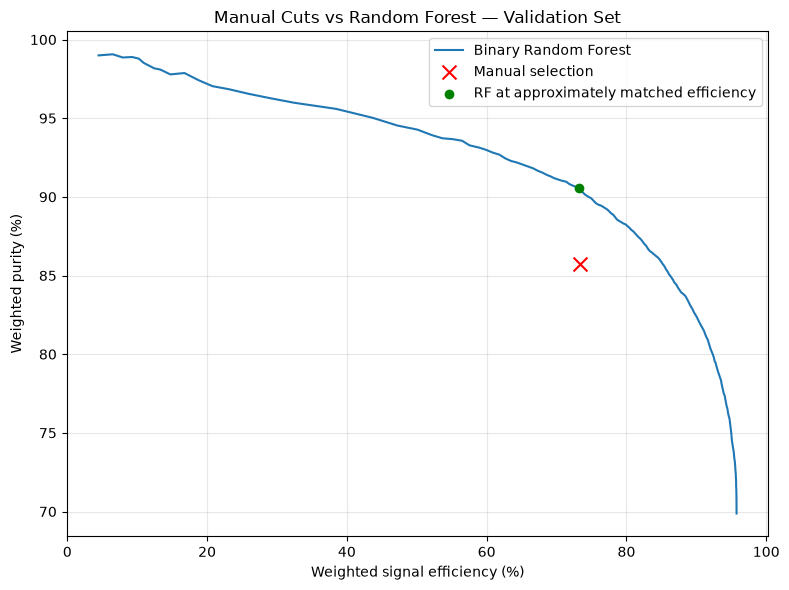

In [6]:
# Evaluate Random Forest at different score thresholds

thresholds = np.linspace(0, 1, 201)

rf_purities = []
rf_efficiencies = []

for threshold in thresholds:
    rf_selected = val_energy_mask & (signal_scores >= threshold)

    purity, efficiency = selection_metrics(
        rf_selected, y_val, w_val
    )

    rf_purities.append(purity)
    rf_efficiencies.append(efficiency)

rf_purities = np.array(rf_purities)
rf_efficiencies = np.array(rf_efficiencies)

# Find the RF threshold closest to manual efficiency
best_idx = np.argmin(np.abs(rf_efficiencies - manual_efficiency))
rf_threshold = float(thresholds[best_idx])

print(f"Manual purity: {manual_purity:.2%}")
print(f"Manual efficiency: {manual_efficiency:.2%}")
print(f"RF threshold: {rf_threshold:.3f}")
print(f"RF purity: {rf_purities[best_idx]:.2%}")
print(f"RF efficiency: {rf_efficiencies[best_idx]:.2%}")

# Plot the performance comparison
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    rf_efficiencies * 100,
    rf_purities * 100,
    label="Binary Random Forest"
)

ax.scatter(
    manual_efficiency * 100,
    manual_purity * 100,
    color="red",
    marker="x",
    s=100,
    label="Manual selection",
    zorder=5
)

ax.scatter(
    rf_efficiencies[best_idx] * 100,
    rf_purities[best_idx] * 100,
    color="green",
    marker="o",
    label="RF at approximately matched efficiency",
    zorder=5
)

ax.set_xlabel("Weighted signal efficiency (%)")
ax.set_ylabel("Weighted purity (%)")
ax.set_title("Manual Cuts vs Random Forest — Validation Set")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 2.4 Evaluate the fixed RF threshold on test data

Apply the validation-selected threshold to the independent test partition. Recalculate the manual reference on the same test rows. A small difference in their test efficiencies is expected; do not adjust the threshold using test data.


In [7]:
# Apply the fixed validation threshold to test scores
test_scores = rf_binary.predict_proba(X_test)[:, 1]
test_energy_mask = analysis_energy_mask(X_test).to_numpy()
manual_selected_test = manual_selection_mask(X_test).to_numpy()
rf_selected_test = test_energy_mask & (test_scores >= rf_threshold)

manual_purity_test, manual_efficiency_test = selection_metrics(
    manual_selected_test, y_test, w_test
)
rf_purity_test, rf_efficiency_test = selection_metrics(
    rf_selected_test, y_test, w_test
)

print(f"Fixed RF threshold: {rf_threshold:.3f}")
print(f"Manual test purity: {manual_purity_test:.2%}")
print(f"Manual test efficiency: {manual_efficiency_test:.2%}")
print(f"RF test purity: {rf_purity_test:.2%}")
print(f"RF test efficiency: {rf_efficiency_test:.2%}")


Fixed RF threshold: 0.745
Manual test purity: 85.97%
Manual test efficiency: 73.01%
RF test purity: 90.21%
RF test efficiency: 72.23%


### 2.5 Inspect RF feature importance

These scores describe the normalised reduction in classification impurity attributed to each feature in the fitted forest. They are not percentages of correctly classified events or the performance loss from removing a feature.


                 feature  importance
3      topological_score    0.481562
15        trk_energy_tot    0.122226
0   _closestNuCosmicDist    0.066506
8    trk_llr_pid_score_v    0.058349
5        trk_sce_end_y_v    0.048208
13     reco_nu_vtx_sce_y    0.041476
1              trk_len_v    0.031429
10     trk_sce_start_y_v    0.026128
7            trk_score_v    0.024541
2         trk_distance_v    0.022024
12     reco_nu_vtx_sce_x    0.017016
11     trk_sce_start_x_v    0.014418
4        trk_sce_end_z_v    0.013507
14     reco_nu_vtx_sce_z    0.012253
9      trk_sce_start_z_v    0.010517
6        trk_sce_end_x_v    0.009840


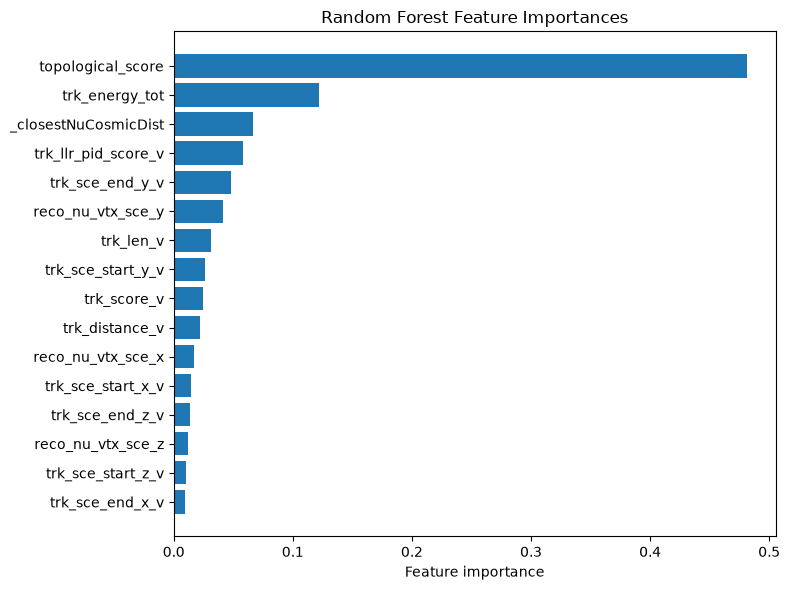

In [8]:
importance_df = pd.DataFrame({
    "feature": features,
    "importance": rf_binary.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance_df["feature"], importance_df["importance"])
ax.invert_yaxis()
ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()


## 3. Physics validation: manual versus RF selection
### 3.1 Build selected MC and real-data samples

Use test-partition MC for both physics selections. Multiply its weights by the inverse sampling fraction (approximately 5) to estimate the expected yield for the full exposure. This rescales the expected yield; it does not restore the MC statistics lost by using only the test partition.

Apply each selection consistently to MC and the full real-data sample. This cell creates the four inputs required by the scan: `MC_manual`, `data_manual`, `MC_rf`, and `data_rf`.


In [9]:
# Retrieve test MC in exactly the same order as X_test and test_scores
MC_test_physics = MC_ML.loc[X_test.index].copy()

# Estimate the full-exposure prediction from the random test partition
mc_scale = len(MC_ML) / len(MC_test_physics)
MC_test_physics["weight"] *= mc_scale

# Prepare real data using the same baseline cleaning as MC
data_physics = pd.read_pickle("data/data_flattened.pkl")
data_physics = data_physics.drop("Subevent", axis=1)
data_physics = data_physics.loc[
    data_physics["trk_energy_tot"] < 1000
].copy()

# Apply the shared manual selection to both samples
MC_manual = MC_test_physics.loc[
    manual_selection_mask(MC_test_physics)
].copy()
data_manual = data_physics.loc[
    manual_selection_mask(data_physics)
].copy()

# Reuse the fixed validation threshold; do not tune it on real data
mc_scores = test_scores
data_scores = rf_binary.predict_proba(data_physics[features])[:, 1]

mc_rf_mask = (
    analysis_energy_mask(MC_test_physics).to_numpy()
    & (mc_scores >= rf_threshold)
)
data_rf_mask = (
    analysis_energy_mask(data_physics).to_numpy()
    & (data_scores >= rf_threshold)
)

MC_rf = MC_test_physics.loc[mc_rf_mask].copy()
data_rf = data_physics.loc[data_rf_mask].copy()

print(f"MC normalisation factor: {mc_scale:.3f}")
print(f"Fixed RF threshold: {rf_threshold:.3f}")
print(f"Manual: {len(MC_manual)} MC rows, {len(data_manual)} data events")
print(f"RF: {len(MC_rf)} MC rows, {len(data_rf)} data events")


MC normalisation factor: 5.000
Fixed RF threshold: 0.745
Manual: 18779 MC rows, 17940 data events
RF: 17937 MC rows, 16717 data events


### 3.2 Run the observed oscillation scans

Only category-21 signal undergoes disappearance. Its weight is multiplied by $1-A_{\mu\mu}\sin^2(1.27\,\Delta m^2 L/E_{\mathrm{true}})$, with $L=0.47\ \mathrm{km}$, $E_{\mathrm{true}}$ in GeV, and $\Delta m^2$ in $\mathrm{eV}^2$. Background weights are unchanged. Spectra are binned in reconstructed energy.

Keep the lab's simplified statistic:

$$\chi^2=\sum_b\frac{(P_b-O_b)^2}{(0.15P_b)^2}.$$

This treats bin uncertainties independently and includes no separate data-statistical or finite-MC statistical term. Both selections use the same binning, parameter grid, and uncertainty prescription.

Define `scan_selected_sample` once. It returns `(grid, baseline, observed)` and calculates chi-squared internally. Supplying `observed=` replaces real data with a reference spectrum for the Asimov calculation below.


In [10]:
# Common oscillation parameter space
bin_edges = np.linspace(0, 2, 21)
dm_compare = np.geomspace(0.02, 100, 121)
amplitude_compare = np.linspace(0, 1, 101)

def scan_selected_sample(mc, data, dm_values, amplitudes, observed=None):
    """Return the chi-squared grid, unoscillated prediction, and target spectrum."""
    # Unoscillated MC prediction
    baseline, _ = np.histogram(
        mc["trk_energy_tot"],
        bins=bin_edges,
        weights=mc["weight"]
    )

    # Observed data, or a supplied reference spectrum
    if observed is None:
        observed, _ = np.histogram(
            data["trk_energy_tot"], bins=bin_edges
        )
    observed = np.asarray(observed, dtype=float)

    # Only nu_mu CC signal undergoes disappearance
    signal = mc.loc[mc["category"] == 21]

    true_E = signal["true_E"].to_numpy(dtype=float)
    reco_E = signal["trk_energy_tot"].to_numpy(dtype=float)
    weights = signal["weight"].to_numpy(dtype=float)

    if not np.all(np.isfinite(true_E) & (true_E > 0)):
        raise ValueError("Signal true_E must be finite and positive.")

    grid = np.empty((len(dm_values), len(amplitudes)))

    for i, dm in enumerate(dm_values):
        phase = 1.27 * dm * 0.47 / true_E

        # Signal yield lost through oscillation in each reco-energy bin
        deficit, _ = np.histogram(
            reco_E,
            bins=bin_edges,
            weights=weights * np.sin(phase)**2
        )

        # Predictions for every amplitude at this delta_m2
        prediction = (
            baseline[None, :]
            - amplitudes[:, None] * deficit[None, :]
        )

        # Labbook's 15% systematic uncertainty approximation
        uncertainty = 0.15 * prediction
        difference = prediction - observed[None, :]

        residuals = np.divide(
            difference,
            uncertainty,
            out=np.zeros_like(prediction),
            where=uncertainty > 0
        )

        values = np.sum(residuals**2, axis=1)

        # Handle bins with zero or invalid predicted uncertainty
        invalid = (
            (uncertainty <= 0)
            & (np.abs(difference) > 1e-9)
        )
        values[np.any(invalid, axis=1)] = np.inf

        grid[i, :] = values

    return grid, baseline, observed


# Run the same analysis for both selections
samples = {
    "Manual": (MC_manual, data_manual),
    "Random Forest": (MC_rf, data_rf)
}

results = {}

for name, (mc, data) in samples.items():
    grid, baseline, observed = scan_selected_sample(
        mc, data, dm_compare, amplitude_compare
    )

    chi2_min = np.min(grid)
    i_best, j_best = np.unravel_index(
        np.argmin(grid), grid.shape
    )

    results[name] = {
        "grid": grid,
        "delta": grid - chi2_min,
        "baseline": baseline,
        "observed": observed
    }

    print(f"\n{name} selection:")
    print(f"Minimum chi2: {chi2_min:.4f}")
    if amplitude_compare[j_best] == 0:
        print("Best delta_m2: unconstrained at zero amplitude")
    else:
        print(f"Best delta_m2 grid point: {dm_compare[i_best]:.4f}")
    print(f"Best amplitude: {amplitude_compare[j_best]:.4f}")
    print(f"No-oscillation chi2: {grid[0, 0]:.4f}")
    print(
        "No-oscillation consistency:",
        np.allclose(grid[:, 0], grid[0, 0])
    )



Manual selection:
Minimum chi2: 19.5122
Best delta_m2: unconstrained at zero amplitude
Best amplitude: 0.0000
No-oscillation chi2: 19.5122
No-oscillation consistency: True



Random Forest selection:
Minimum chi2: 25.4236
Best delta_m2 grid point: 4.4026
Best amplitude: 0.0400
No-oscillation chi2: 25.8901
No-oscillation consistency: True


### 3.3 Plot the observed constraints alongside LSND and MiniBooNE

Reuse the observed scans; this cell only converts the horizontal axis and plots the two panels. Use the small-mixing branch with fixed $A_{ee}=0.24$:

$$A_{\mu e}=\left(1-\sqrt{1-A_{\mu\mu}}\right)\left(1-\sqrt{1-A_{ee}}\right).$$

Subtract each selection's own minimum chi-squared. The contour levels 4.605, 5.991, and 9.210 are the nominal two-parameter 90%, 95%, and 99% thresholds used here. Their exact coverage is not calibrated in this simplified analysis. An observed contour also depends on data-model agreement, so use the next section for an expected-sensitivity comparison.


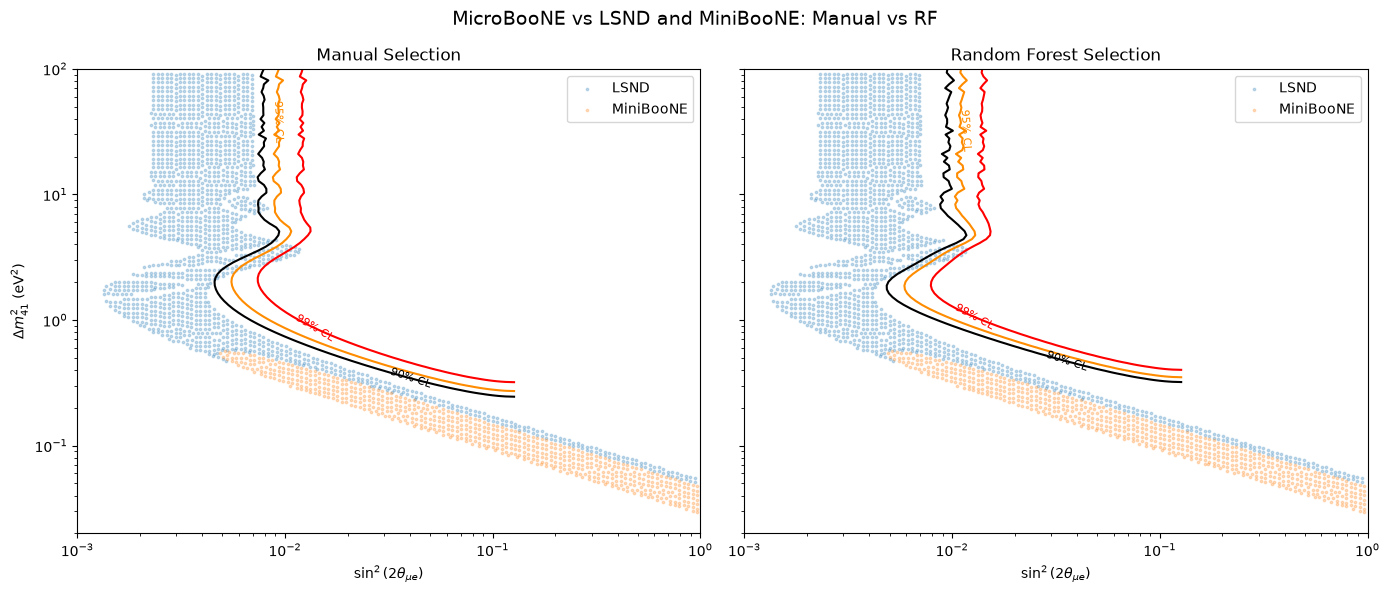

In [11]:
# Convert muon disappearance to muon-electron appearance
def appearance_amplitude(A_mumu, A_ee=0.24):
    return (
        (1 - np.sqrt(1 - A_mumu))
        * (1 - np.sqrt(1 - A_ee))
    )

appearance_values = appearance_amplitude(amplitude_compare)

# Exclude zero from the logarithmic x-axis
positive = appearance_values > 0

# Nominal confidence levels for two fitted parameters
cl_levels = [4.605, 5.991, 9.210]
cl_labels = {
    4.605: "90% CL",
    5.991: "95% CL",
    9.210: "99% CL"
}

# Load LSND and MiniBooNE reference regions
LSND_data = pd.read_csv(
    "data/DataSet_LSND.csv"
).to_numpy()

MiniBooNE_data = pd.read_csv(
    "data/DataSet_MiniBooNE.csv"
).to_numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    sharex=True, sharey=True
)

for ax, (name, result) in zip(axes, results.items()):

    ax.scatter(
        LSND_data[:, 0], LSND_data[:, 1],
        s=3, alpha=0.25, label="LSND"
    )

    ax.scatter(
        MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
        s=3, alpha=0.25, label="MiniBooNE"
    )

    # Set logarithmic axes before placing contour labels
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(0.02, 100)

    contours = ax.contour(
        appearance_values[positive],
        dm_compare,
        result["delta"][:, positive],
        levels=cl_levels,
        colors=["black", "darkorange", "red"],
        linewidths=1.5
    )

    ax.clabel(
        contours,
        fmt=cl_labels,
        fontsize=8,
        inline=False
    )

    ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
    ax.set_title(f"{name} Selection")
    ax.legend(loc="upper right")

axes[0].set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")

fig.suptitle(
    "MicroBooNE vs LSND and MiniBooNE: Manual vs RF",
    fontsize=14
)

plt.tight_layout()

# Save the final comparison
fig.savefig(
    output_dir / "observed_ex14_manual_vs_rf.png",
    dpi=200, bbox_inches="tight"
)

plt.show()


### 3.4 Compare expected sensitivity with no-oscillation Asimov spectra

For each selection, use its own unoscillated MC prediction as the reference spectrum, with no random fluctuations. This asks how strongly that selection could constrain disappearance if data matched its baseline prediction, under the same 15% uncertainty approximation.

Both minimum chi-squared values should be zero. At a fixed mass splitting, a smaller appearance-amplitude limit means a stronger expected constraint.


Manual Asimov minimum chi2: 0.000000
Random Forest Asimov minimum chi2: 0.000000


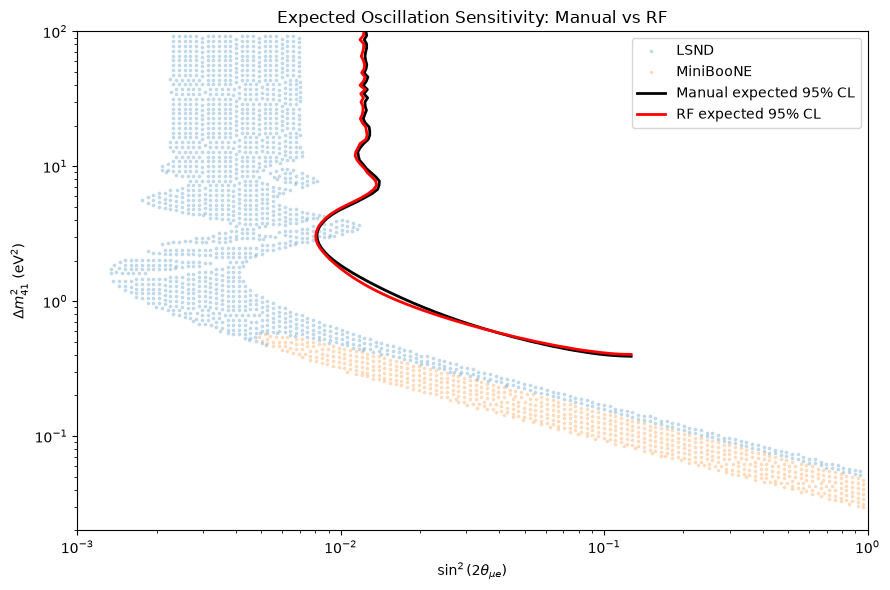

In [12]:
# Expected sensitivity using no-oscillation Asimov spectra
asimov_results = {}

for name, (mc, data) in samples.items():
    # Use each selection's unoscillated MC prediction
    asimov_target = results[name]["baseline"]

    grid, _, _ = scan_selected_sample(
        mc,
        data,
        dm_compare,
        amplitude_compare,
        observed=asimov_target
    )

    asimov_results[name] = grid - np.min(grid)

    print(
        f"{name} Asimov minimum chi2:",
        f"{np.min(grid):.6f}"
    )


# Compare expected 95% CL contours
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    LSND_data[:, 0], LSND_data[:, 1],
    s=3, alpha=0.2, label="LSND"
)

ax.scatter(
    MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
    s=3, alpha=0.2, label="MiniBooNE"
)

for name, color in [
    ("Manual", "black"),
    ("Random Forest", "red")
]:
    ax.contour(
        appearance_values[positive],
        dm_compare,
        asimov_results[name][:, positive],
        levels=[5.991],
        colors=[color],
        linewidths=2
    )

from matplotlib.lines import Line2D

handles, labels = ax.get_legend_handles_labels()

handles.extend([
    Line2D([0], [0], color="black", lw=2),
    Line2D([0], [0], color="red", lw=2)
])
labels.extend([
    "Manual expected 95% CL",
    "RF expected 95% CL"
])

ax.legend(handles, labels)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-3, 1)
ax.set_ylim(0.02, 100)

ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
ax.set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")
ax.set_title("Expected Oscillation Sensitivity: Manual vs RF")

plt.tight_layout()

fig.savefig(
    output_dir / "expected_95cl_manual_vs_rf.png",
    dpi=200, bbox_inches="tight"
)

plt.show()


### 3.5 Quantify the expected 95% limits

For each requested mass splitting, use the nearest scanned mass and interpolate the first crossing of the 95% threshold along the amplitude axis. Print the actual scanned mass as well as the requested value. `RF / Manual < 1` indicates a stronger RF limit; `NaN` means the scan did not reach the threshold.


In [13]:
# Quantify expected 95% CL limits at selected mass splittings

def expected_limit(dm_target, method, level=5.991):
    # Find the nearest scanned mass splitting
    i = np.argmin(np.abs(dm_compare - dm_target))

    delta_chi2 = asimov_results[method][i]

    # Find the first crossing of the confidence threshold
    crossings = np.where(delta_chi2 >= level)[0]

    if len(crossings) == 0:
        return np.nan

    j = crossings[0]

    if j == 0:
        return appearance_values[0]

    return np.interp(
        level,
        delta_chi2[j-1:j+1],
        appearance_values[j-1:j+1]
    )


print("Target dm2 | Scanned dm2 | Manual limit | RF limit | RF / Manual")

for dm in [0.5, 1, 3, 10, 30]:
    scanned_dm = dm_compare[np.argmin(np.abs(dm_compare - dm))]
    manual = expected_limit(dm, "Manual")
    rf = expected_limit(dm, "Random Forest")

    print(
        f"{dm:10.1f} | "
        f"{scanned_dm:11.4f} | "
        f"{manual:12.5f} | "
        f"{rf:8.5f} | "
        f"{rf/manual:11.3f}"
    )


Target dm2 | Scanned dm2 | Manual limit | RF limit | RF / Manual
       0.5 |      0.4877 |      0.05670 |  0.05940 |       1.048
       1.0 |      0.9917 |      0.01835 |  0.01683 |       0.917
       3.0 |      3.0874 |      0.00812 |  0.00805 |       0.990
      10.0 |     10.3183 |      0.01217 |  0.01189 |       0.977
      30.0 |     29.9212 |      0.01236 |  0.01194 |       0.966


## 4. Neural network extension
### 4.1 Standardise inputs and train the network

Use the same features and data split as RF. Fit the scaler only on training features, then apply it to validation features. Divide both training and validation weights by the training mean weight; this preserves their relative weighting.

The network has two hidden layers (32 and 16 units) and one sigmoid output. Train for at most 60 epochs with weighted binary cross-entropy. Early stopping monitors validation loss and restores the best weights. This section trains the NN; its selection threshold is chosen in the next section.


In [14]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

# Start a fresh model when this cell is rerun
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Standardise inputs using training data only
scaler_nn = StandardScaler()

X_train_nn = scaler_nn.fit_transform(X_train).astype("float32")
X_val_nn = scaler_nn.transform(X_val).astype("float32")

y_train_nn = y_train.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")

# Normalise event weights for stable training
weight_scale = w_train.mean()

w_train_nn = w_train.to_numpy(dtype="float32") / weight_scale
w_val_nn = w_val.to_numpy(dtype="float32") / weight_scale

# Build a small feed-forward neural network
nn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(len(features),)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy"
)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    sample_weight=w_train_nn,
    validation_data=(X_val_nn, y_val_nn, w_val_nn),
    epochs=60,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=2
)

nn_model.summary()


Epoch 1/60


353/353 - 1s - 3ms/step - loss: 0.5062 - val_loss: 0.4613


Epoch 2/60


353/353 - 0s - 626us/step - loss: 0.4552 - val_loss: 0.4492


Epoch 3/60


353/353 - 0s - 623us/step - loss: 0.4449 - val_loss: 0.4425


... (116 outputs left out)

 Total params: 3,269 (12.77 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,180 (8.52 KB)

### 4.2 Choose the NN threshold on validation data

Scan the NN signal score and match the same manual validation efficiency used for RF. Use the shared `val_energy_mask` array and report the weighted metrics. The RF and NN may have different score thresholds because their score distributions differ.

These are validation results used to select `nn_threshold`. Section 4.3 applies that fixed threshold to test data; the threshold is not retuned using test or real-data results.


In [15]:
# Build the validation mask explicitly, independent of earlier kernel state
val_energy_mask = analysis_energy_mask(X_val).to_numpy()

# Predict NN signal scores on validation data
nn_scores_val = nn_model.predict(
    X_val_nn, verbose=0
).ravel()

nn_thresholds = np.linspace(0, 1, 501)

nn_purities = []
nn_efficiencies = []

for threshold in nn_thresholds:
    selected = val_energy_mask & (nn_scores_val >= threshold)

    purity, efficiency = selection_metrics(
        selected, y_val, w_val
    )

    nn_purities.append(purity)
    nn_efficiencies.append(efficiency)

nn_purities = np.array(nn_purities)
nn_efficiencies = np.array(nn_efficiencies)

# Match the manual selection efficiency
nn_best_idx = np.argmin(
    np.abs(nn_efficiencies - manual_efficiency)
)

nn_threshold = nn_thresholds[nn_best_idx]

print(f"NN threshold: {nn_threshold:.3f}")
print(f"NN validation purity: {nn_purities[nn_best_idx]:.2%}")
print(f"NN validation efficiency: {nn_efficiencies[nn_best_idx]:.2%}")

print(f"\nRF purity (validation): {rf_purities[best_idx]:.2%}")
print(f"RF efficiency (validation): {rf_efficiencies[best_idx]:.2%}")


NN threshold: 0.744
NN validation purity: 89.56%
NN validation efficiency: 73.50%

RF purity (validation): 90.55%
RF efficiency (validation): 73.27%


### 4.3 Compare manual cuts, RF, and NN on the test set

Transform test features using the scaler fitted on training data, then predict NN signal scores. Reuse the NN threshold selected in Section 4.2 and the RF threshold from Section 2.3.

All three methods use the same test rows, event weights, energy window, and baseline-signal efficiency denominator. The thresholds approximately matched manual efficiency on validation data; their test efficiencies can differ. This table is a test evaluation, not a new threshold scan.


In [16]:
# Apply the training-fitted scaler without fitting it again
X_test_nn = scaler_nn.transform(X_test).astype("float32")
nn_scores_test = nn_model.predict(X_test_nn, verbose=0).ravel()

# Freeze both score thresholds at their validation-selected values
nn_selected_test = test_energy_mask & (nn_scores_test >= nn_threshold)

test_selections = {
    "Manual cuts": manual_selected_test,
    "Random Forest": rf_selected_test,
    "Neural Network": nn_selected_test,
}
fixed_thresholds = {
    "Manual cuts": np.nan,
    "Random Forest": rf_threshold,
    "Neural Network": nn_threshold,
}

# Recalculate all metrics on the same test sample for a direct comparison
test_rows = []
for name, selected in test_selections.items():
    purity, efficiency = selection_metrics(selected, y_test, w_test)
    test_rows.append({
        "Method": name,
        "Score threshold": fixed_thresholds[name],
        "Weighted purity (%)": 100 * purity,
        "Weighted efficiency (%)": 100 * efficiency,
    })

test_comparison = pd.DataFrame(test_rows)
print(test_comparison.to_string(
    index=False,
    na_rep="--",
    formatters={
        "Score threshold": "{:.3f}".format,
        "Weighted purity (%)": "{:.2f}".format,
        "Weighted efficiency (%)": "{:.2f}".format,
    },
))


        Method Score threshold Weighted purity (%) Weighted efficiency (%)
   Manual cuts              --               85.97                   73.01
 Random Forest           0.745               90.21                   72.23
Neural Network           0.744               89.44                   72.77


## 5. Observed oscillation comparison: manual cuts, RF, and NN
### 5.1 Prepare NN-selected samples and scan their oscillation parameters

Reuse the test MC with the exposure-normalised weights from Section 3.1. Its row order matches `X_test`, so the NN test mask selects the corresponding MC events. Apply the same trained scaler, NN model, energy window, and fixed NN threshold to real data.

Reuse `scan_selected_sample` with the existing reconstructed-energy bins and oscillation grid. As before, only category-21 signal oscillates and each predicted bin has a 15% uncertainty. The earlier manual and RF scans are reused; only the NN scan is new.


In [17]:
# The test mask and MC_test_physics share the X_test row order
MC_nn = MC_test_physics.loc[nn_selected_test].copy()

# Apply the same scaler and fixed NN threshold to real data
X_data_nn = scaler_nn.transform(data_physics[features]).astype("float32")
nn_scores_data = nn_model.predict(X_data_nn, verbose=0).ravel()
data_nn_mask = (
    analysis_energy_mask(data_physics).to_numpy()
    & (nn_scores_data >= nn_threshold)
)
data_nn = data_physics.loc[data_nn_mask].copy()

print(f"Fixed NN threshold: {nn_threshold:.3f}")
print(f"MC normalisation factor: {mc_scale:.3f}")
print(f"NN: {len(MC_nn)} MC rows, {len(data_nn)} data events")

# Scan NN with the same function and parameter grid as manual cuts and RF
nn_grid, nn_baseline, nn_observed = scan_selected_sample(
    MC_nn, data_nn, dm_compare, amplitude_compare
)
nn_chi2_min = np.min(nn_grid)
nn_i_best, nn_j_best = np.unravel_index(np.argmin(nn_grid), nn_grid.shape)

nn_result = {
    "grid": nn_grid,
    "delta": nn_grid - nn_chi2_min,
    "baseline": nn_baseline,
    "observed": nn_observed,
}

# Preserve the earlier two-method results and build a separate comparison
comparison_results = {
    "Manual cuts": results["Manual"],
    "Random Forest": results["Random Forest"],
    "Neural Network": nn_result,
}

print(f"NN minimum chi2: {nn_chi2_min:.4f}")
if amplitude_compare[nn_j_best] == 0:
    print("NN best delta_m2: unconstrained at zero amplitude")
else:
    print(f"NN best delta_m2 grid point: {dm_compare[nn_i_best]:.4f}")
print(f"NN best amplitude: {amplitude_compare[nn_j_best]:.4f}")
print(f"NN no-oscillation chi2: {nn_grid[0, 0]:.4f}")
print("NN no-oscillation consistency:", np.allclose(nn_grid[:, 0], nn_grid[0, 0]))


Fixed NN threshold: 0.744
MC normalisation factor: 5.000
NN: 18188 MC rows, 17022 data events
NN minimum chi2: 15.3754
NN best delta_m2 grid point: 4.4026
NN best amplitude: 0.0200
NN no-oscillation chi2: 15.5066
NN no-oscillation consistency: True


### 5.2 Plot all three observed constraints alongside LSND and MiniBooNE

Each panel shows the same reference regions and the nominal 90%, 95%, and 99% contours, using the appearance-amplitude conversion with fixed $A_{ee}=0.24$. Subtract each selection's own minimum chi-squared. The axes, scan range, and colour convention are identical across panels.

These are **observed constraints**: their positions depend on the agreement between each selected real-data spectrum and its MC prediction. A stronger-looking observed contour alone does not demonstrate better expected sensitivity. The purity and efficiency table above separately measures classification performance on labelled test MC.

This plotting cell reuses the three computed grids. Changing the layout or labels does not require retraining the models or repeating the scans.


Saved figure: output/ml_selection/observed_ex14_manual_vs_rf_vs_nn.png


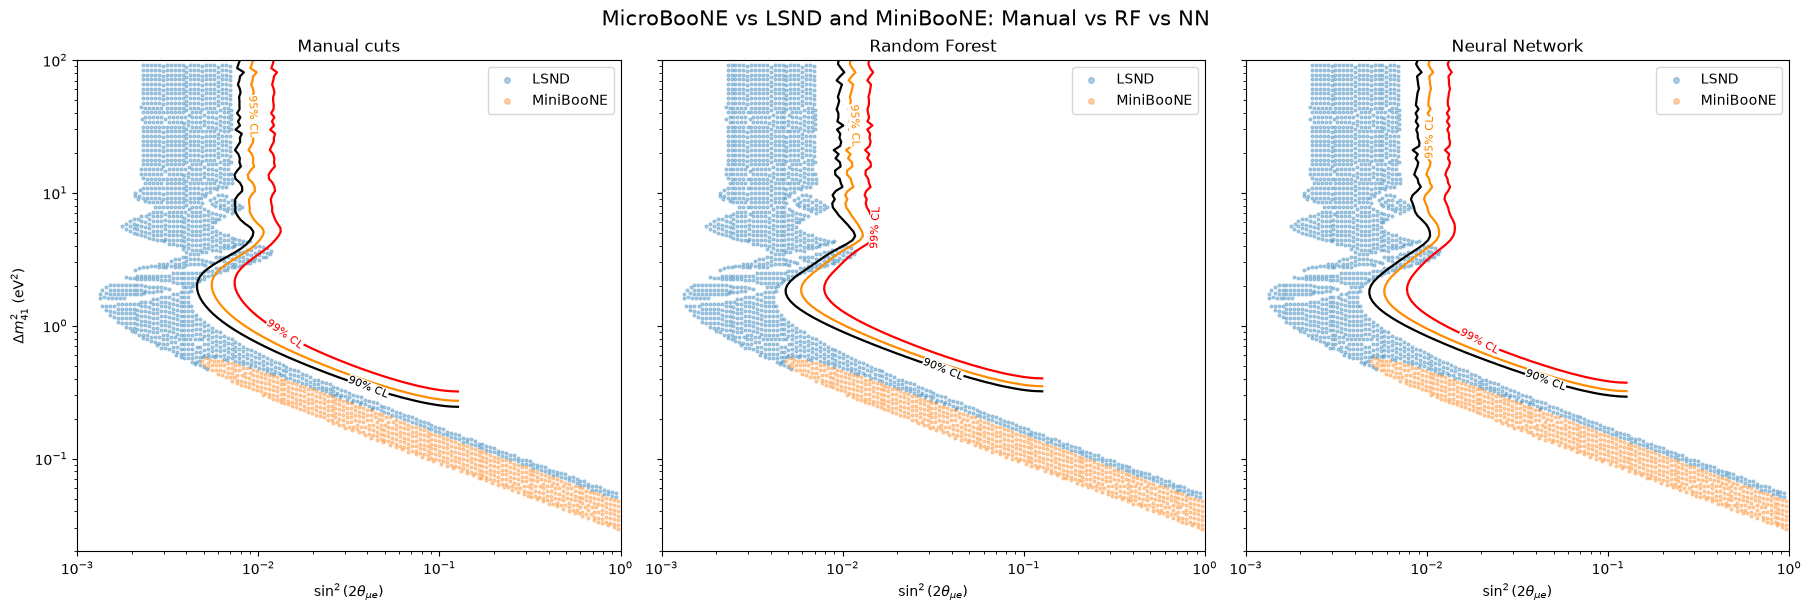

In [18]:
# Plot one panel per selection using the already computed chi-squared grids
fig, axes = plt.subplots(
    1, 3, figsize=(18, 6), sharex=True, sharey=True,
    layout="constrained",
)

for ax, (name, result) in zip(axes, comparison_results.items()):
    ax.scatter(
        LSND_data[:, 0], LSND_data[:, 1],
        s=4, alpha=0.35, color="tab:blue", label="LSND",
    )
    ax.scatter(
        MiniBooNE_data[:, 0], MiniBooNE_data[:, 1],
        s=4, alpha=0.35, color="tab:orange", label="MiniBooNE",
    )

    # Set log axes before placing contour labels
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(0.02, 100)

    contours = ax.contour(
        appearance_values[positive],
        dm_compare,
        result["delta"][:, positive],
        levels=cl_levels,
        colors=["black", "darkorange", "red"],
        linewidths=1.6,
    )
    contour_labels = ax.clabel(
        contours, fmt=cl_labels, fontsize=8, inline=False,
    )
    # Keep text readable without deleting segments of the contour paths
    for label in contour_labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 0.3})

    ax.set_title(name)
    ax.set_xlabel(r"$\sin^2(2\theta_{\mu e})$")
    ax.legend(loc="upper right", markerscale=2)

axes[0].set_ylabel(r"$\Delta m_{41}^2$ (eV$^2$)")
fig.suptitle("MicroBooNE vs LSND and MiniBooNE: Manual vs RF vs NN", fontsize=15)

comparison_plot_path = output_dir / "observed_ex14_manual_vs_rf_vs_nn.png"
fig.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
print(f"Saved figure: {comparison_plot_path}")
plt.show()


## Further Investigation: Why does improved classification not strongly improve oscillation sensitivity?